# 1. Problem: exchange maps from dynamic MR signals

This is an active reconstruction of the full **existing noisy QIBA v6 digital phantom**, not a patient acquisition. Two spatial fields are inferred: transfer $K$ (min$^{-1}$) and extracellular fraction $v$ (dimensionless). Every one of 3,000 native pixels remains included. Independent phantom parameters are actual truth; original reproduced source results are a separate comparison.

The selected complete published estimator performs unconstrained nonlinear fitting and then clips its physical maps. Raw fitting alone failed physical parameter quality. The complete estimator is informative but biased, particularly in weak washout regions. We retain those failures in the figures.

In [1]:
import os,sys,time,json,hashlib,subprocess
from pathlib import Path
os.environ['OPENBLAS_NUM_THREADS']='1';os.environ['OMP_NUM_THREADS']='1'
# Execution launcher sets this before kernel creation; no shared environment edit.
assert os.environ.get('OPENBLAS_CORETYPE')=='Prescott'
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0,str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from src.preprocessing import load_observations,prepare_curves
from src.physics_model import conv
from src.solvers import reconstruct,fit
from src.generate_data import perturb_signal
from src.visualization import export_figure,field_image
FIG=Path(os.environ['QIBA_FIGURE_DIR']);FIG.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.size':10,'figure.constrained_layout.use':True})
def save(fig,name,**arrays):
    export_figure(fig,FIG,name,arrays);plt.show();plt.close(fig)
def measures(a,b):
    x=a.ravel();y=b.ravel()
    return np.array([np.dot(x,y)/(np.linalg.norm(x)*np.linalg.norm(y)),np.sqrt(np.mean((x-y)**2))/np.ptp(y)])
obs=load_observations(ROOT/'data/raw_data.npz')
with np.load(ROOT/'evaluation/ground_truth.npz',allow_pickle=False) as f:truth={k:f[k] for k in f.files}
with np.load(ROOT/'notebooks/reference_outputs/upstream_result.npz',allow_pickle=False) as f:original={k:f[k] for k in f.files}
keys=['ktrans','extracellular_fraction'];units=['min$^{-1}$','fraction']
print('Raw SHA256',hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest())
print('Condition: existing author simulation; full support',obs['signal'].shape)


Raw SHA256 90868ba674e547381647762c97099346ec97b084af612aa07f0faf89af030377
Condition: existing author simulation; full support (1, 1321, 60, 50)


# 2. Data: full native time series and legitimate calibration

The author-supplied existing noisy magnitude observations contain 1,321 samples at 0.5 s spacing over 660 s. Calibration is precontrast R0, constant flip angle 30 degrees, TR 5 ms and relaxivity 4.5 s^-1 mM^-1. Plasma input is already hematocrit corrected. The source's unused clean S0 map is deliberately not an input. The measured first two dynamic frames provide baseline normalization. Raster axes remain native row and column indices; no spatial interpolation or cropping is used.

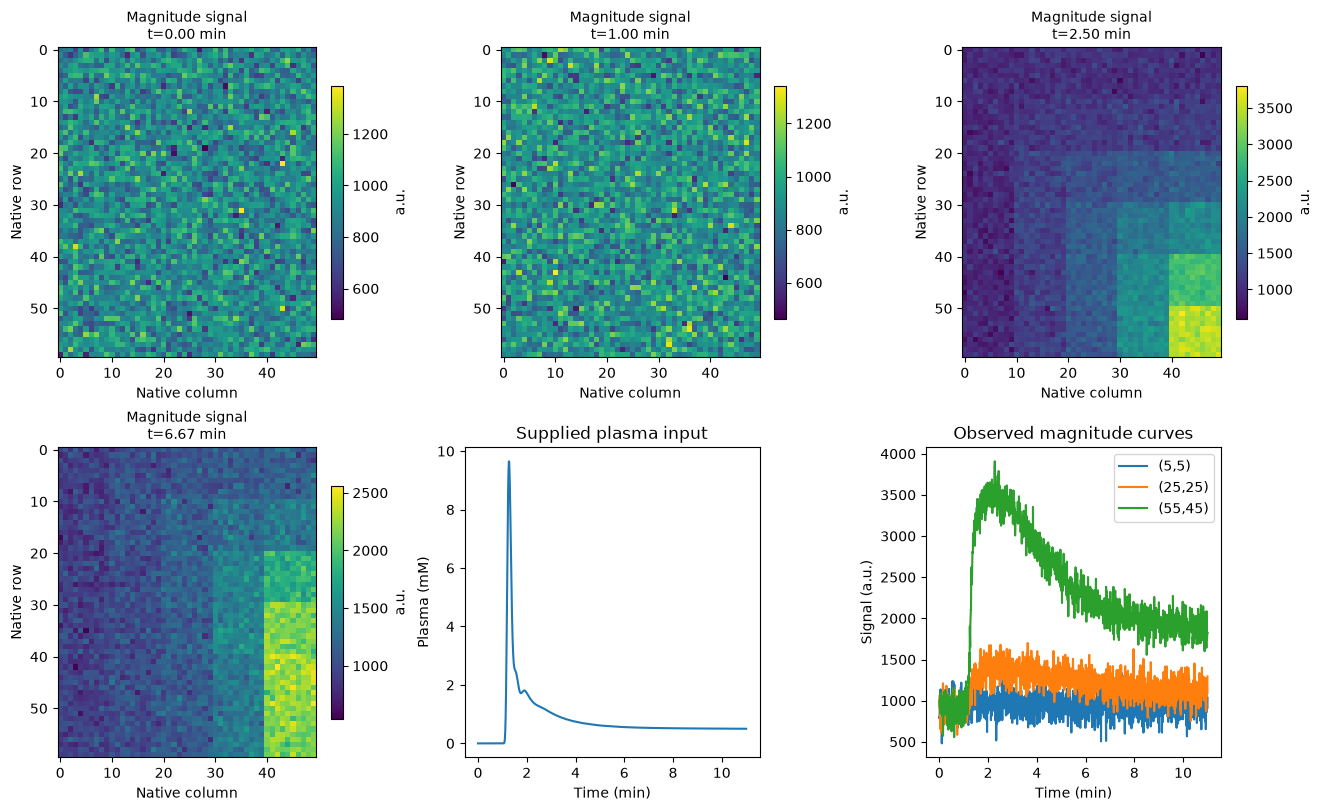

In [2]:
signal=obs['signal'][0];time_minutes=obs['time_seconds'][0]/60;cp=obs['plasma_concentration'][0]
frames=[0,120,300,800]
fig,axs=plt.subplots(2,3,figsize=(13,8))
for ax,j in zip(axs.ravel(),frames):field_image(ax,signal[j],f'Magnitude signal\nt={time_minutes[j]:.2f} min','a.u.')
axs[1,1].plot(time_minutes,cp);axs[1,1].set(xlabel='Time (min)',ylabel='Plasma (mM)',title='Supplied plasma input')
for r,c in [(5,5),(25,25),(55,45)]:axs[1,2].plot(time_minutes,signal[:,r,c],label=f'({r},{c})')
axs[1,2].set(xlabel='Time (min)',ylabel='Signal (a.u.)',title='Observed magnitude curves');axs[1,2].legend()
save(fig,'fig01_observations',signal_frames=signal[frames],frame_indices=np.array(frames),time_minutes=time_minutes,plasma=cp,curves=signal[:,[5,25,55],[5,25,45]])


# 3. Physics: signal conversion and causal tissue response

For signal ratio $a=S/S_b$, baseline exponential $E_0=e^{-T_RR_0}$ and $c=cos	heta$, the inverted exponential is

$$E=(1-a+aE_0-E_0c)/(1-ac+aE_0c-E_0c),\quad R=-\log(E)/T_R,\quad C=(R-R_0)/r_1.$$

The standard exchange model is $C(t)=K\int_0^t C_p(\tau)e^{-k(t-\tau)}d\tau$, where $k=K/v$ is the efflux rate. Plasma is linearly interpolated between samples; exponential integration is analytic over each interval. Zero vascular-volume contribution and zero initial concentration are fixed assumptions. Additional negative or invalid signal-conversion branches follow the original implementation and never remove scored positions. The finite measured baseline makes this noisy concentration estimate biased.

The 2015 paper described trapezoid integration; the selected later source revision uses the Flouri Appendix exponential recurrence. This notebook evaluates that selected revision, not an undocumented mixture of the two.

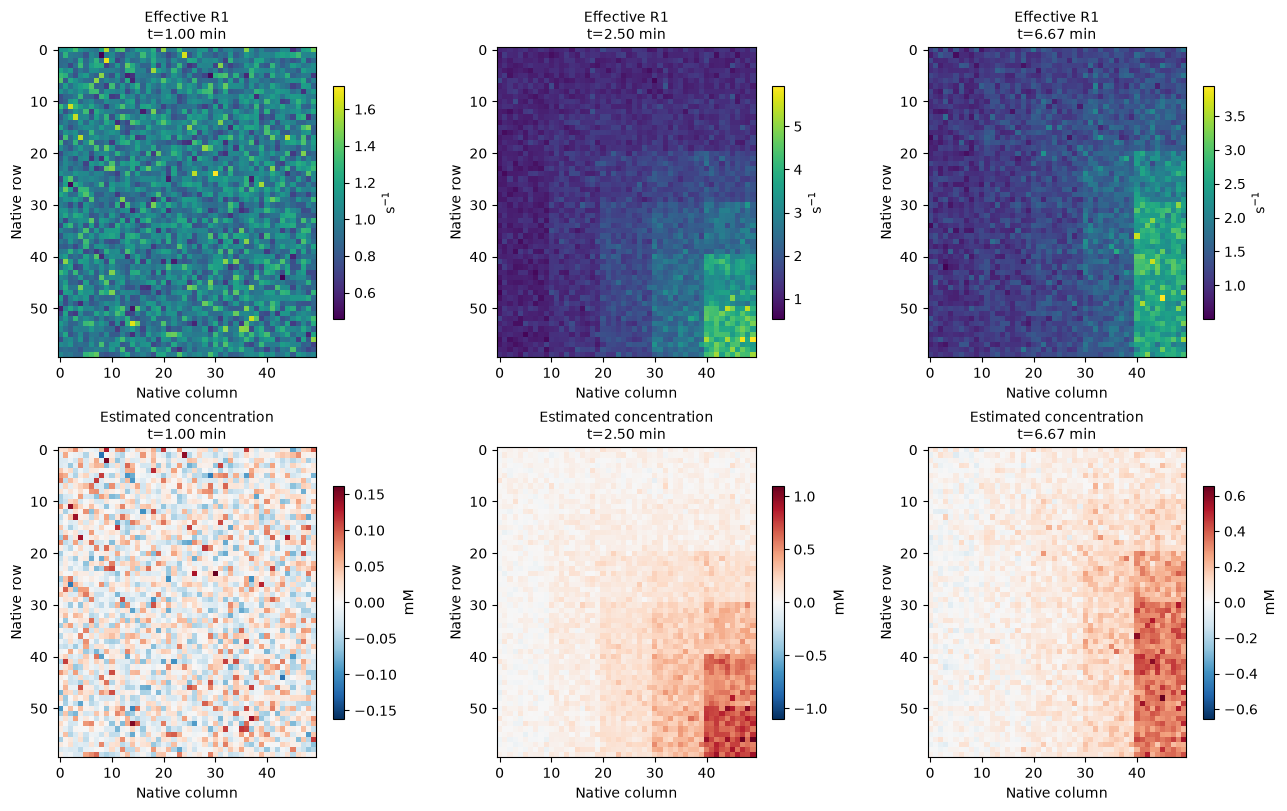

In [3]:
r1,ct,t,cp=prepare_curves(obs)
fig,axs=plt.subplots(2,3,figsize=(13,8))
for j,ax in zip([120,300,800],axs[0]):field_image(ax,r1[:,j].reshape(60,50,order='F'),f'Effective R1\nt={t[j]:.2f} min','s$^{-1}$')
for j,ax in zip([120,300,800],axs[1]):field_image(ax,ct[:,j].reshape(60,50,order='F'),f'Estimated concentration\nt={t[j]:.2f} min','mM',signed=True)
save(fig,'fig02_signal_physics',r1=r1[:,[120,300,800]],concentration=ct[:,[120,300,800]])


# 4. Method: active complete published estimator

Each pixel minimizes the full unnormalized concentration SSE in coordinates $(K,k)$ using a damped Gauss-Newton/Levenberg-Marquardt method. A central-difference Jacobian, accepted/rejected trial steps, damping adjustments and original stopping tests are implemented locally. The final published maps are clipped to the declared physical ranges. All 3,000 locations are retained regardless of any diagnostic mask.

This cell freshly reconstructs the raw observations. No original result or cached reconstruction is used as its input. Task-scoped one-thread numerical conventions preserve the independently frozen Julia oracle arithmetic; they do not turn the original reconstruction into ground truth.

D:\yan1\agent\AutoSkill\imaging-101-release\tasks\qiba_dce_exchange_maps\src\physics_model.py:68: RuntimeWarning: overflow encountered in multiply
  v[...,0,0]=a[...,0]*a[...,0]+a[...,1]*a[...,1]


Fresh complete reconstruction seconds 103.0054941999988
All-field original parity DR-NRMSE {'ktrans': 1.3966800251885089e-08, 'extracellular_fraction': 3.6847175871996323e-10}
Independent truth Judge {
  "ktrans_ncc": 0.9229122642099193,
  "ktrans_nrmse": 0.19474377794859662,
  "extracellular_fraction_ncc": 0.9322052296269518,
  "extracellular_fraction_nrmse": 0.1890152437119966
}


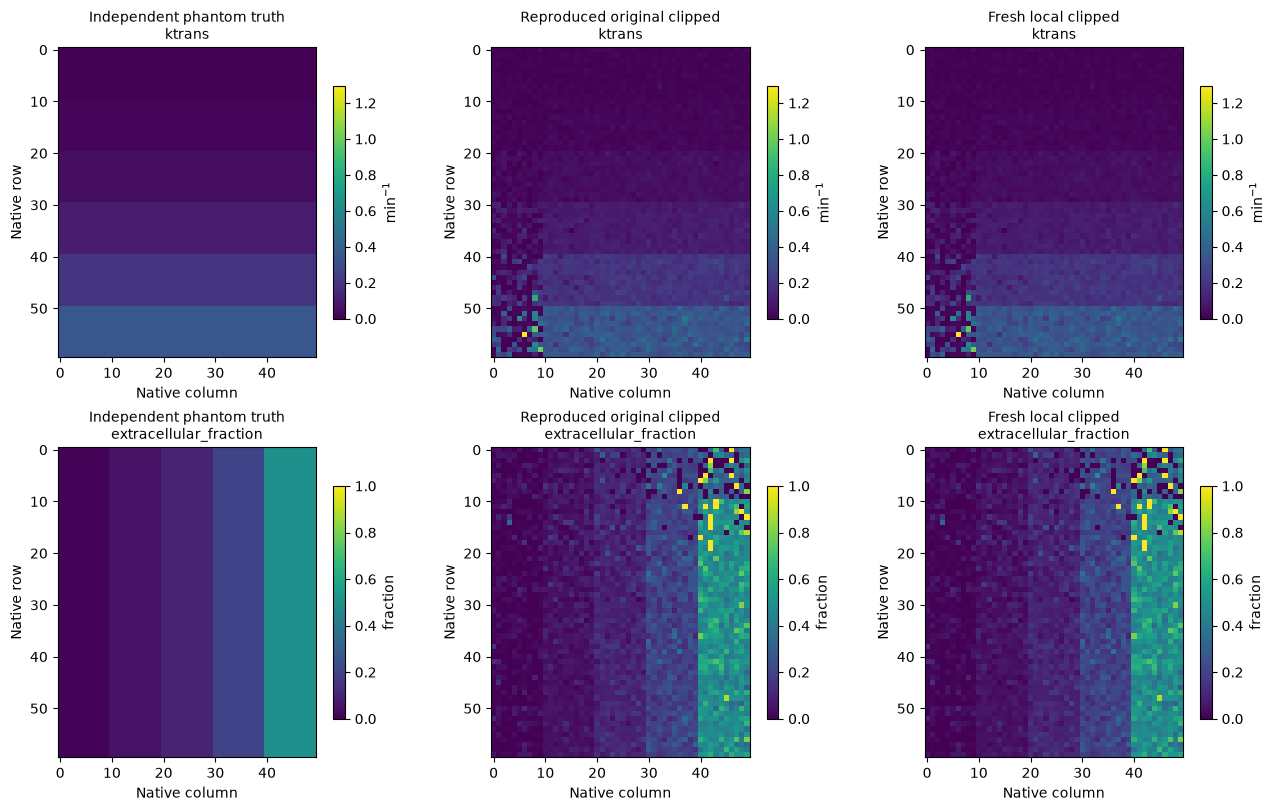

In [4]:
started=time.perf_counter();fresh,diag=reconstruct(obs);runtime=time.perf_counter()-started
np.savez_compressed(ROOT/'output/reconstruction.npz',**fresh)
result=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True)
assert result.returncode==0,result.stderr.decode(errors='replace')
report=json.loads((ROOT/'output/judge_report.json').read_text())
parity={k:float(np.sqrt(np.mean((fresh[k]-original[k])**2))/np.ptp(original[k])) for k in keys}
assert all(v<=1e-6 for v in parity.values()),parity
print('Fresh complete reconstruction seconds',runtime)
print('All-field original parity DR-NRMSE',parity)
print('Independent truth Judge',json.dumps(report['metrics'],indent=2))
fig,axs=plt.subplots(2,3,figsize=(13,8))
for i,k in enumerate(keys):
    limit=(0,float(max(truth[k].max(),original[k].max(),fresh[k].max())))
    for j,(name,data) in enumerate([('Independent phantom truth',truth),('Reproduced original clipped',original),('Fresh local clipped',fresh)]):
        field_image(axs[i,j],data[k][0],f'{name}\n{k}',units[i],limit)
save(fig,'fig03_maps',**{f'{a}_{k}':d[k] for a,d in [('truth',truth),('original',original),('fresh',fresh)] for k in keys})


# 5. Results: accuracy, causal consistency and sensitivity

Truth metrics use cosine similarity without subtracting a mean and dynamic-range-normalized RMS error. Original reproduction and fresh local output are labeled separately. Both are imperfect estimates of independently specified phantom parameters. The following figures expose spatial errors, raw-versus-clipped behavior, full causal residuals, initialization and noise sensitivity, and convergence rather than masking difficult pixels.

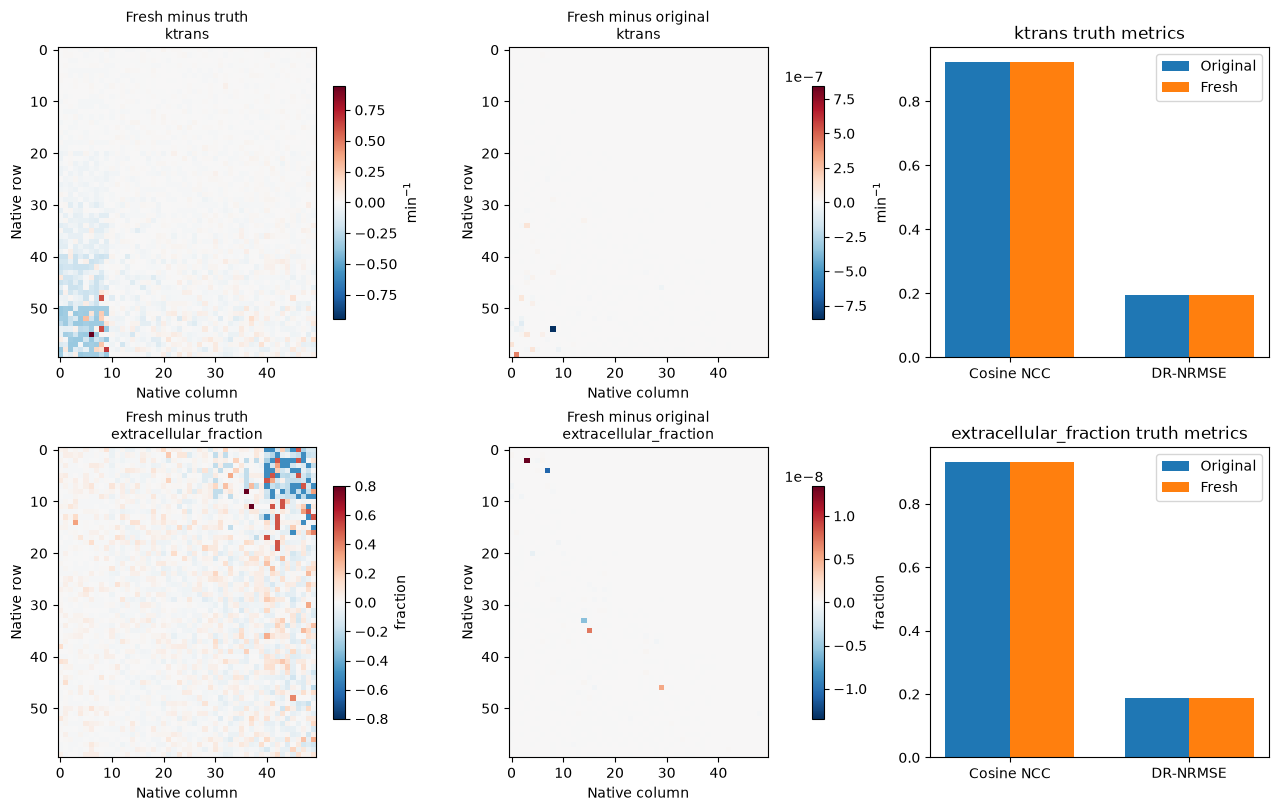

Raw unphysical K/fraction pixels 252 ; scored support 3000


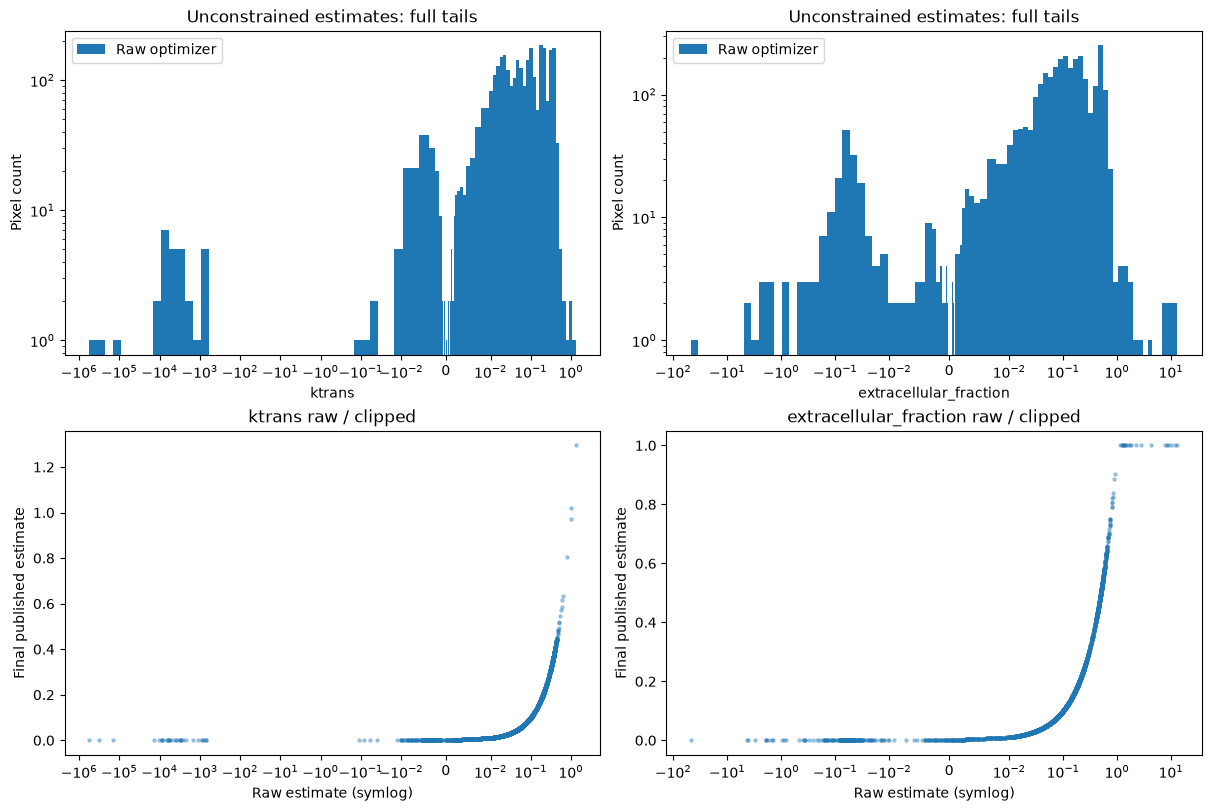

In [5]:
fig,axs=plt.subplots(2,3,figsize=(13,8));metric_rows=[]
for i,k in enumerate(keys):
    field_image(axs[i,0],(fresh[k]-truth[k])[0],f'Fresh minus truth\n{k}',units[i],signed=True)
    field_image(axs[i,1],(fresh[k]-original[k])[0],f'Fresh minus original\n{k}',units[i],signed=True)
    vals=np.array([measures(original[k],truth[k]),measures(fresh[k],truth[k])]);metric_rows.append(vals)
    x=np.arange(2);axs[i,2].bar(x-.18,vals[0],.36,label='Original');axs[i,2].bar(x+.18,vals[1],.36,label='Fresh')
    axs[i,2].set(xticks=x,xticklabels=['Cosine NCC','DR-NRMSE'],title=k+' truth metrics');axs[i,2].legend()
save(fig,'fig04_errors_metrics',metric_values=np.array(metric_rows),**{f'error_truth_{k}':fresh[k]-truth[k] for k in keys},**{f'error_original_{k}':fresh[k]-original[k] for k in keys})
raw=diag['raw_rates'];raw_v=raw[:,0]/raw[:,1]
fig,axs=plt.subplots(2,2,figsize=(12,8))
for ax,values,k in zip(axs[0],[raw[:,0],raw_v],keys):
    ax.hist(values,bins=np.unique(np.r_[-np.geomspace(1e-8,max(1.,abs(values.min())),70)[::-1],0,np.geomspace(1e-8,max(1.,values.max()),100)]),label='Raw optimizer')
    ax.set_xscale('symlog',linthresh=.01);ax.set_yscale('log');ax.set(xlabel=k,ylabel='Pixel count',title='Unconstrained estimates: full tails');ax.legend()
for ax,values,k in zip(axs[1],[raw[:,0],raw_v],keys):
    ax.scatter(values,fresh[k].ravel(order='F'),s=5,alpha=.35);ax.set_xscale('symlog',linthresh=.01);ax.set(xlabel='Raw estimate (symlog)',ylabel='Final published estimate',title=k+' raw / clipped')
invalid=int(np.count_nonzero((raw[:,0]<=0)|(raw_v<=0)|(raw_v>1)))
print('Raw unphysical K/fraction pixels',invalid,'; scored support',3000)
save(fig,'fig05_raw_clipped',raw_rates=raw,raw_fraction=raw_v,ktrans=fresh['ktrans'],fraction=fresh['extracellular_fraction'])


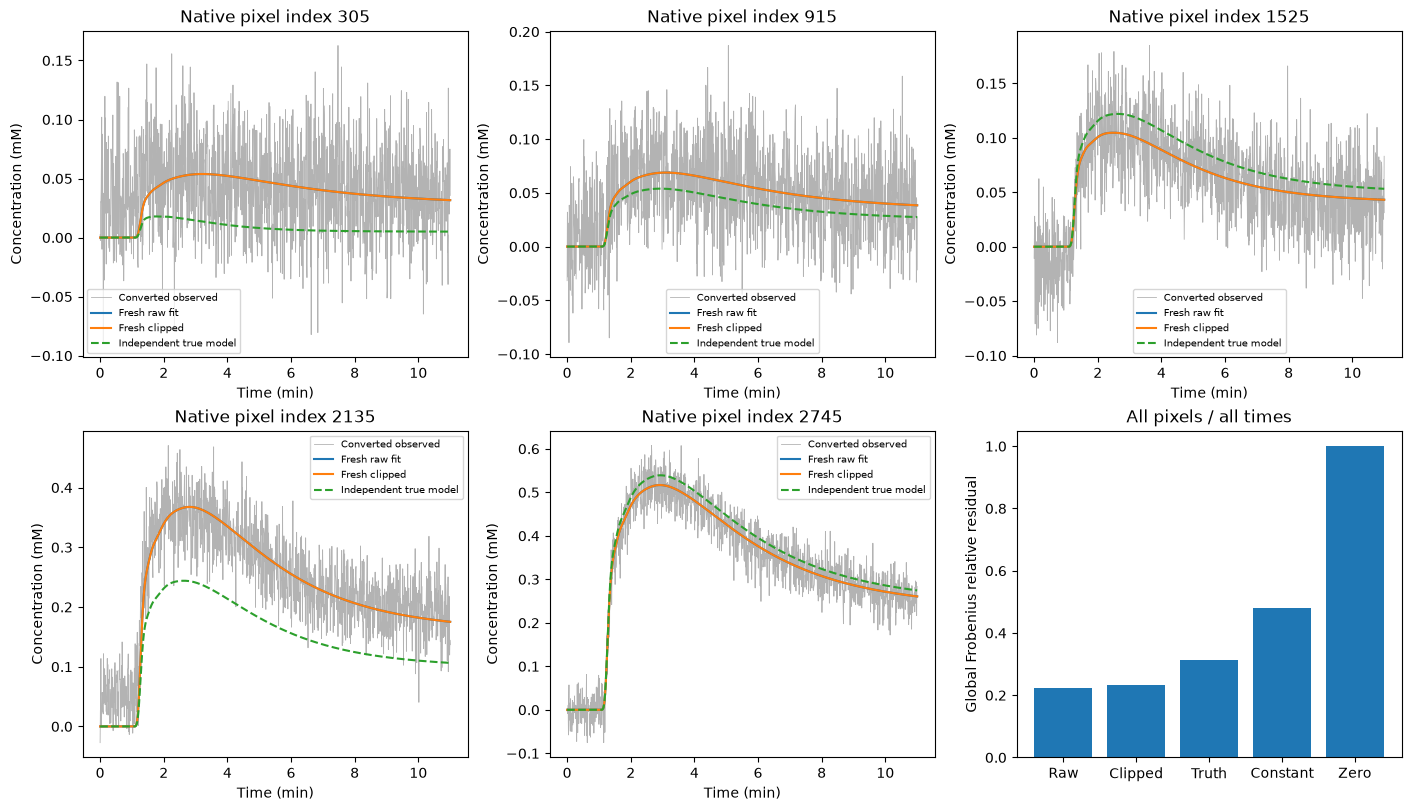

Global causal residuals: raw/clipped/truth/constant/zero [0.22327333 0.23450839 0.31268997 0.4812284  1.        ]


In [6]:
K=fresh['ktrans'][0].ravel(order='F');V=fresh['extracellular_fraction'][0].ravel(order='F')
pred=K[:,None]*conv(cp,K/V,t)
Kt=truth['ktrans'][0].ravel(order='F');Vt=truth['extracellular_fraction'][0].ravel(order='F')
pred_truth=Kt[:,None]*conv(cp,Kt/Vt,t)
pred_raw=ct+diag['residual']
null=np.broadcast_to(ct.mean(1)[:,None],ct.shape)
norm=np.linalg.norm(ct)
forward=np.array([np.linalg.norm(pred_raw-ct),np.linalg.norm(pred-ct),np.linalg.norm(pred_truth-ct),np.linalg.norm(null-ct),norm])/norm
fig,axs=plt.subplots(2,3,figsize=(14,8));chosen=[305,915,1525,2135,2745]
for ax,index in zip(axs.ravel(),chosen):
    ax.plot(t,ct[index],color='.7',lw=.6,label='Converted observed');ax.plot(t,pred_raw[index],label='Fresh raw fit');ax.plot(t,pred[index],label='Fresh clipped');ax.plot(t,pred_truth[index],'--',label='Independent true model')
    ax.set(xlabel='Time (min)',ylabel='Concentration (mM)',title=f'Native pixel index {index}');ax.legend(fontsize=7)
axs[1,2].bar(np.arange(5),forward);axs[1,2].set(xticks=np.arange(5),xticklabels=['Raw','Clipped','Truth','Constant','Zero'],ylabel='Global Frobenius relative residual',title='All pixels / all times')
save(fig,'fig06_causal_quality',selected_indices=np.array(chosen),time_minutes=t,observed=ct[chosen],raw=pred_raw[chosen],clipped=pred[chosen],true_model=pred_truth[chosen],all_domain_relative_residual=forward)
print('Global causal residuals: raw/clipped/truth/constant/zero',forward)


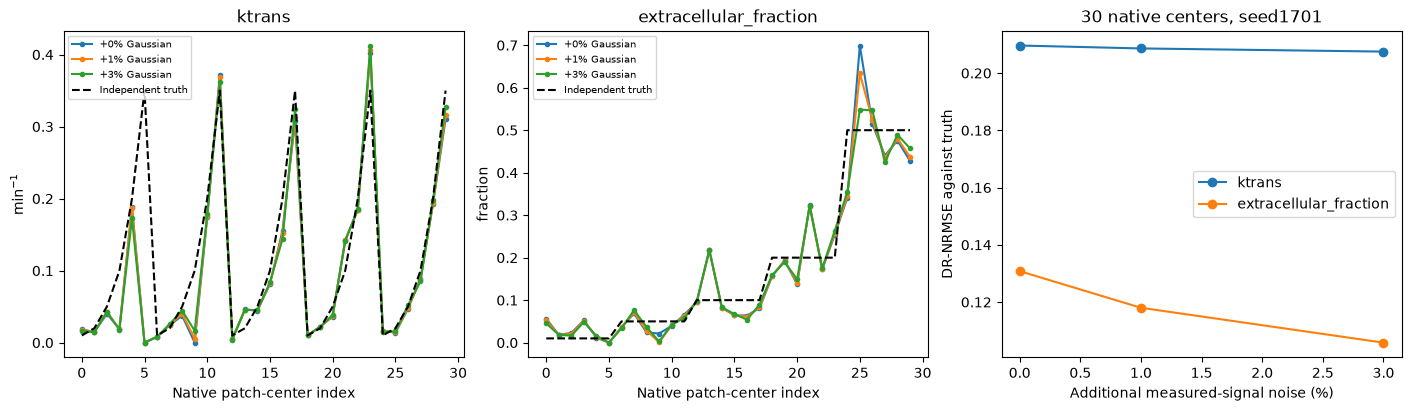

In [7]:
# Native patch centers are a small disclosed sensitivity set; baseline scoring remains full.
indices=np.array([r+60*c for c in range(5,50,10) for r in range(5,60,10)])
sigmas=[0.,.01,.03];noise_values=[];noise_metrics=[]
for sigma in sigmas:
    pert=perturb_signal(obs,sigma,1701)
    _,cc,_,_=prepare_curves(pert)
    pp,_,_=fit(cc[indices],t,cp)
    vv=np.column_stack([np.clip(pp[:,0],np.finfo(float).eps,5),np.clip(pp[:,0]/pp[:,1],np.finfo(float).eps,1)])
    noise_values.append(vv)
    noise_metrics.append([measures(vv[:,0],Kt[indices])[1],measures(vv[:,1],Vt[indices])[1]])
noise_values=np.array(noise_values);noise_metrics=np.array(noise_metrics)
fig,axs=plt.subplots(1,3,figsize=(14,4))
for j,k in enumerate(keys):
    for i,sigma in enumerate(sigmas):axs[j].plot(noise_values[i,:,j],'.-',label=f'+{100*sigma:g}% Gaussian')
    axs[j].plot([Kt,Vt][j][indices],'k--',label='Independent truth');axs[j].set(xlabel='Native patch-center index',ylabel=units[j],title=k);axs[j].legend(fontsize=7)
axs[2].plot(np.array(sigmas)*100,noise_metrics,'o-');axs[2].set(xlabel='Additional measured-signal noise (%)',ylabel='DR-NRMSE against truth',title='30 native centers, seed1701');axs[2].legend(keys)
save(fig,'fig07_added_noise',indices=indices,sigmas=np.array(sigmas),values=noise_values,metrics=noise_metrics,truth=np.column_stack([Kt[indices],Vt[indices]]))


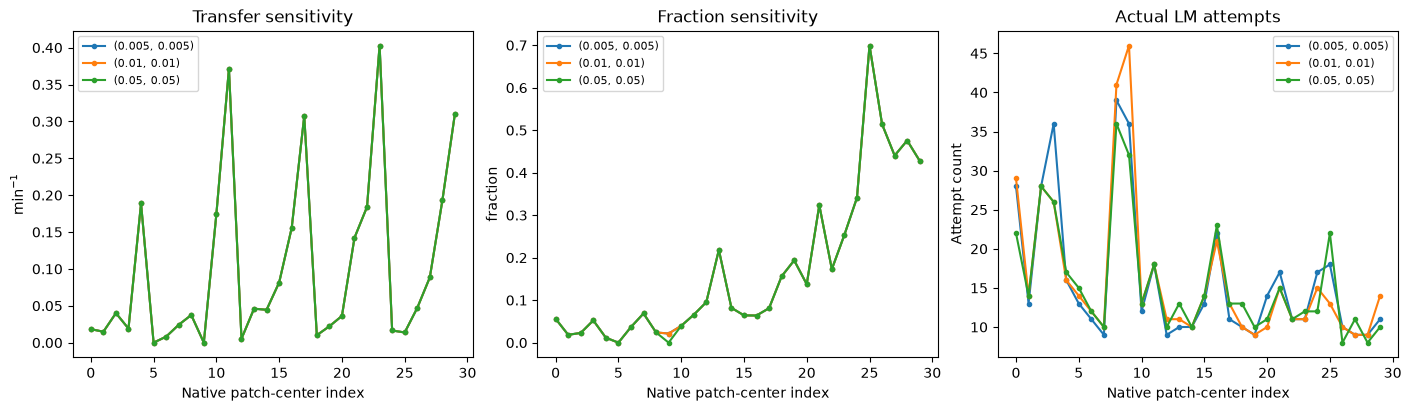

In [8]:
initials=[(.005,.005),(.01,.01),(.05,.05)];init_values=[];init_cost=[];init_iterations=[]
for initial in initials:
    pp,rr,ii=fit(ct[indices],t,cp,initial=initial)
    init_values.append(np.column_stack([np.clip(pp[:,0],np.finfo(float).eps,5),np.clip(pp[:,0]/pp[:,1],np.finfo(float).eps,1)]));init_cost.append(np.sum(rr*rr,axis=1));init_iterations.append(ii)
init_values=np.array(init_values);init_cost=np.array(init_cost);init_iterations=np.array(init_iterations)
fig,axs=plt.subplots(1,3,figsize=(14,4))
for i,initial in enumerate(initials):
    axs[0].plot(init_values[i,:,0],'.-',label=str(initial));axs[1].plot(init_values[i,:,1],'.-',label=str(initial));axs[2].plot(init_iterations[i],'.-',label=str(initial))
for ax,title in zip(axs,['Transfer sensitivity','Fraction sensitivity','Actual LM attempts']):ax.set(xlabel='Native patch-center index',title=title);ax.legend(fontsize=8)
axs[0].set_ylabel('min$^{-1}$');axs[1].set_ylabel('fraction');axs[2].set_ylabel('Attempt count')
save(fig,'fig08_initialization',indices=indices,initials=np.array(initials),values=init_values,costs=init_cost,iterations=init_iterations)


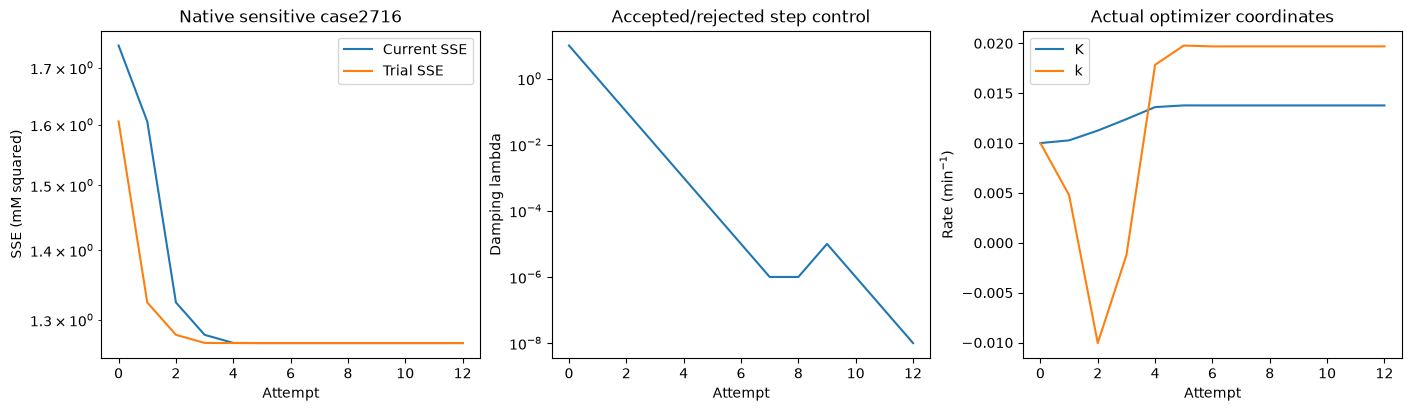

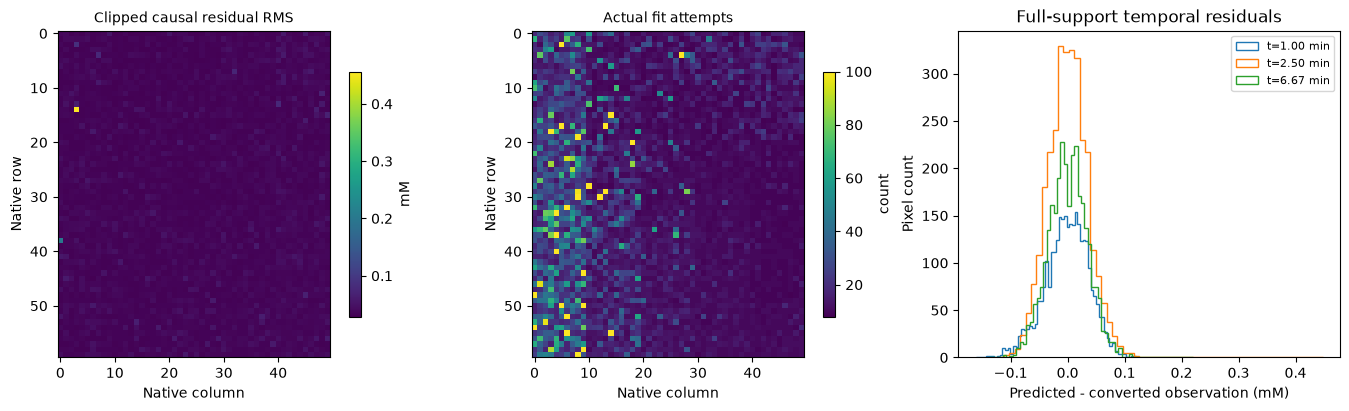

{'fresh_reconstruction_seconds': 103.0054941999988,
 'source_parity_dr_nrmse': {'ktrans': 1.3966800251885089e-08,
  'extracellular_fraction': 3.6847175871996323e-10},
 'truth_metrics': {'ktrans_ncc': 0.9229122642099193,
  'ktrans_nrmse': 0.19474377794859662,
  'extracellular_fraction_ncc': 0.9322052296269518,
  'extracellular_fraction_nrmse': 0.1890152437119966},
 'forward_global_relative_l2': [0.2232733312872163,
  0.23450838707332236,
  0.31268997185688513,
  0.4812284021852408,
  1.0],
 'raw_unphysical_pixels': 252,
 'support_pixels': 3000,
 'noise_experiment_seed': 1701,
 'noise_sigmas': [0.0, 0.01, 0.03]}

In [9]:
trace=[];case=2715;fit(ct[case:case+1],t,cp,trace=trace)
tr=np.array([z['scalars'][0] for z in trace]);pp=np.array([z['x'][0] for z in trace])
fig,axs=plt.subplots(1,3,figsize=(14,4))
axs[0].semilogy(tr[:,1],label='Current SSE');axs[0].semilogy(tr[:,3],label='Trial SSE');axs[0].set(xlabel='Attempt',ylabel='SSE (mM squared)',title='Native sensitive case2716');axs[0].legend()
axs[1].semilogy(tr[:,0]);axs[1].set(xlabel='Attempt',ylabel='Damping lambda',title='Accepted/rejected step control')
axs[2].plot(pp);axs[2].set(xlabel='Attempt',ylabel='Rate (min$^{-1}$)',title='Actual optimizer coordinates');axs[2].legend(['K','k'])
save(fig,'fig09_convergence',iteration_scalars=tr,parameter_history=pp)
fig,axs=plt.subplots(1,3,figsize=(14,4))
residual=pred-ct
field_image(axs[0],np.sqrt(np.mean(residual**2,axis=1)).reshape(60,50,order='F'),'Clipped causal residual RMS','mM')
field_image(axs[1],diag['iterations'].reshape(60,50,order='F'),'Actual fit attempts','count')
for j in [120,300,800]:axs[2].hist(residual[:,j],bins=60,histtype='step',label=f't={t[j]:.2f} min')
axs[2].set(xlabel='Predicted - converted observation (mM)',ylabel='Pixel count',title='Full-support temporal residuals');axs[2].legend(fontsize=8)
save(fig,'fig10_residual_support',rms=np.sqrt(np.mean(residual**2,axis=1)),iterations=diag['iterations'],residual_snapshots=residual[:,[120,300,800]])
summary={'fresh_reconstruction_seconds':runtime,'source_parity_dr_nrmse':parity,'truth_metrics':report['metrics'],'forward_global_relative_l2':forward.tolist(),'raw_unphysical_pixels':invalid,'support_pixels':3000,'noise_experiment_seed':1701,'noise_sigmas':sigmas}
(FIG/'experiment_summary.json').write_text(json.dumps(summary,indent=2,allow_nan=False))
summary


# 6. Conclusion and limitations

The active full-raster local result meets the predeclared all-field truth criteria and the independently frozen original parity limits. The complete clipped estimator explains converted observations better than the predefined constant and zero nulls, while clipping changes the causal fit and introduces visible bias. The raw unconstrained fit is not a reliable parameter-map estimator on this noisy phantom; its tails remain visible.

These results validate the selected published digital-phantom estimator and numerical extraction, not absolute accuracy on a patient. Magnitude noise and two-frame baseline normalization bias concentration; weak washout, initialization and source stopping behavior affect identifiability. Additional Gaussian perturbations are sensitivity experiments on already noisy measurements, not confidence intervals or new independent patient data. All pixels and both physical fields remain included. Source/data licenses, source-version distinctions, frozen fixtures and execution hashes are recorded in validation.md.